# 01 – Phân tích khám phá dữ liệu (EDA) – Online Retail II

**Đề tài:** Phân khúc khách hàng thương mại điện tử dựa trên mô hình RFM kết hợp các thuật toán phân cụm trên tập dữ liệu Online Retail II.

**Mục tiêu notebook:** hiểu bản chất dữ liệu trước khi tiền xử lý: kích thước, kiểu dữ liệu, phân phối, dữ liệu thiếu, dữ liệu trùng, giá trị bất thường/ngoại lệ, đặc điểm theo thời gian, quốc gia, sản phẩm và khách hàng. Kết quả của notebook này là danh sách **quyết định tiền xử lý** được thực hiện ở notebook `02_preprocessing_RFM.ipynb`.

**Phạm vi dữ liệu:** nhóm sử dụng sheet *Year 2010-2011* của bộ Online Retail II (UCI Machine Learning Repository, id 502), gồm các giao dịch từ **01/12/2010 đến 09/12/2011** của một công ty bán lẻ trực tuyến tại Vương quốc Anh, chuyên bán quà tặng; nhiều khách hàng là nhà bán buôn.

## 1. Khai báo thư viện và đọc dữ liệu

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # để import thư mục src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from src.data_utils import load_raw, is_non_product
from src import viz
viz.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 20)

df = load_raw()          # lần đầu đọc từ Excel (~20s), các lần sau đọc từ cache parquet
print("Kích thước:", df.shape)
df.head()

Kích thước: (541910, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 2. Tổng quan cấu trúc dữ liệu
### 2.1 Ý nghĩa các thuộc tính

In [2]:
meta = pd.DataFrame({
    "Thuộc tính": df.columns,
    "Kiểu dữ liệu": df.dtypes.astype(str).values,
    "Số giá trị khác nhau": [df[c].nunique() for c in df.columns],
    "Ý nghĩa": [
        "Mã hóa đơn (6 chữ số); bắt đầu bằng 'C' = hóa đơn hủy, 'A' = điều chỉnh nợ xấu",
        "Mã sản phẩm (5 chữ số, có thể kèm chữ cái); một số mã đặc biệt như POST, M, D",
        "Tên sản phẩm",
        "Số lượng sản phẩm trong dòng giao dịch (âm nếu trả hàng)",
        "Thời điểm lập hóa đơn",
        "Đơn giá (bảng Anh, £)",
        "Mã khách hàng (5 chữ số)",
        "Quốc gia của khách hàng",
    ],
})
meta

,Thuộc tính,Kiểu dữ liệu,Số giá trị khác nhau,Ý nghĩa
0,Invoice,str,25900,Mã hóa đơn (6 chữ số); bắt đầu bằng 'C' = hóa ...
1,StockCode,str,4070,"Mã sản phẩm (5 chữ số, có thể kèm chữ cái); mộ..."
2,Description,str,4223,Tên sản phẩm
3,Quantity,int64,722,Số lượng sản phẩm trong dòng giao dịch (âm nếu...
4,InvoiceDate,datetime64[us],23260,Thời điểm lập hóa đơn
5,Price,float64,1630,"Đơn giá (bảng Anh, £)"
6,Customer ID,float64,4372,Mã khách hàng (5 chữ số)
7,Country,str,38,Quốc gia của khách hàng


In [3]:
summary = {
    "Số dòng giao dịch": len(df),
    "Số hóa đơn": df["Invoice"].nunique(),
    "Số khách hàng (có ID)": df["Customer ID"].nunique(),
    "Số mã sản phẩm": df["StockCode"].nunique(),
    "Số quốc gia": df["Country"].nunique(),
    "Ngày bắt đầu": df["InvoiceDate"].min(),
    "Ngày kết thúc": df["InvoiceDate"].max(),
    "Dung lượng bộ nhớ (MB)": round(df.memory_usage(deep=True).sum() / 1024**2, 1),
}
pd.Series(summary, name="Giá trị").to_frame()

,Giá trị
Số dòng giao dịch,541910
Số hóa đơn,25900
Số khách hàng (có ID),4372
Số mã sản phẩm,4070
Số quốc gia,38
Ngày bắt đầu,2010-12-01 08:26:00
Ngày kết thúc,2011-12-09 12:50:00
Dung lượng bộ nhớ (MB),59.50


**Nhận xét:**
- Bộ dữ liệu có **541.910 dòng × 8 thuộc tính**. Mỗi dòng là **một sản phẩm trong một hóa đơn**, không phải một hóa đơn và cũng không phải một khách hàng. Vì vậy để phân khúc khách hàng phải **tổng hợp (aggregate) về cấp khách hàng**: đây chính là vai trò của mô hình RFM.
- Có 25.900 hóa đơn, 4.372 khách hàng có mã, khoảng 4.070 mã sản phẩm và 38 quốc gia, trải dài khoảng 1 năm (01/12/2010 – 09/12/2011). Quy mô này đủ lớn và phức tạp cho bài toán khai phá dữ liệu.
- `Customer ID` đang ở kiểu `float` do có giá trị thiếu (NaN) và cần chuyển về `int` sau khi xử lý.

### 2.2 Thống kê mô tả các thuộc tính số

In [4]:
df[["Quantity", "Price"]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,"541,910.00",9.55,218.08,"-80,995.00",-2.00,1.00,1.00,3.00,10.00,29.00,100.00,"80,995.00"
Price,"541,910.00",4.61,96.76,"-11,062.06",0.19,0.42,1.25,2.08,4.13,9.95,18.00,"38,970.00"


**Nhận xét:**
- `Quantity` và `Price` đều có **giá trị âm** (min = −80.995 và −11.062,06) và **giá trị cực lớn** (max = 80.995 và 38.970), trong khi trung vị chỉ là 3 sản phẩm và 2,08 £.
- 98% số dòng có Quantity trong khoảng [−2; 100] và Price trong khoảng [0,19; 18]. Phân phối **lệch phải rất mạnh**, và độ lệch chuẩn lớn hơn trung bình hàng chục lần. Các giá trị âm và cực trị cần được tìm hiểu nguyên nhân ở mục 4 và 5 trước khi quyết định xử lý.

## 3. Dữ liệu thiếu và dữ liệu trùng lặp

,Số giá trị thiếu,% thiếu
Invoice,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,135080,24.93
Country,0,0.00


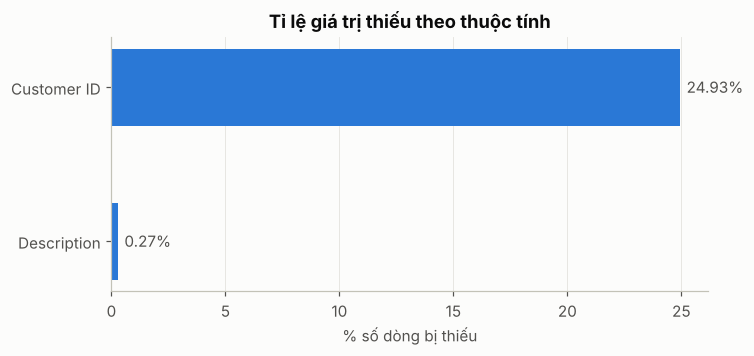

In [5]:
miss = pd.DataFrame({"Số giá trị thiếu": df.isna().sum(),
                     "% thiếu": (100 * df.isna().mean()).round(2)})
display(miss)

fig, ax = plt.subplots(figsize=(7, 3))
m = miss[miss["Số giá trị thiếu"] > 0].sort_values("% thiếu")
ax.barh(m.index, m["% thiếu"], color=viz.MAIN, height=0.5)
for i, v in enumerate(m["% thiếu"]):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center", color=viz.INK2)
ax.set_xlabel("% số dòng bị thiếu"); ax.set_title("Tỉ lệ giá trị thiếu theo thuộc tính")
ax.grid(axis="y", visible=False)
viz.save(fig, "fig01_missing_values"); plt.show()

In [6]:
# Dòng thiếu Customer ID phân bố thế nào?
no_id = df["Customer ID"].isna()
print(f"Tỉ lệ doanh thu (Quantity*Price) đến từ dòng thiếu ID: "
      f"{100 * (df.loc[no_id, 'Quantity'] * df.loc[no_id, 'Price']).sum() / (df['Quantity'] * df['Price']).sum():.2f}%")
print("Dòng thiếu Description có Customer ID không? ->", df.loc[df["Description"].isna(), "Customer ID"].notna().sum(), "dòng có ID")
print("Đơn giá của dòng thiếu Description:", df.loc[df["Description"].isna(), "Price"].unique()[:5])

Tỉ lệ doanh thu (Quantity*Price) đến từ dòng thiếu ID: 14.85%
Dòng thiếu Description có Customer ID không? -> 0 dòng có ID
Đơn giá của dòng thiếu Description: [0.]


In [7]:
dup = df.duplicated()
print(f"Số dòng trùng lặp hoàn toàn: {dup.sum():,} ({100 * dup.mean():.2f}%)")
df[df.duplicated(keep=False)].sort_values(["Invoice", "StockCode"]).head(6)

Số dòng trùng lặp hoàn toàn: 5,268 (0.97%)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom


**Nhận xét:**
- **Customer ID thiếu 24,93%** (135.080 dòng). Các dòng này đóng góp khoảng 14,85% doanh thu. Tuy nhiên bài toán là phân khúc **khách hàng**, nên một giao dịch không xác định được khách hàng thì không thể gán vào hồ sơ RFM nào, và cũng không có cơ sở hợp lý để điền giá trị (impute) cho mã khách hàng. → **Quyết định: loại bỏ các dòng thiếu Customer ID.** Đây là hạn chế của dữ liệu và sẽ được ghi vào báo cáo.
- **Description thiếu 0,27%** (1.454 dòng). Toàn bộ các dòng này đều có Price = 0 và **không có Customer ID**, nên sẽ tự động bị loại ở bước trên.
- **5.268 dòng trùng lặp hoàn toàn** (0,97%): cùng hóa đơn, sản phẩm, số lượng, giá và thời điểm. Khả năng cao đây là lỗi ghi nhận hai lần. → **Quyết định: loại bỏ trùng lặp.**

## 4. Giá trị bất thường: hóa đơn hủy, số lượng âm, đơn giá bằng 0, mã không phải sản phẩm

In [8]:
inv_type = df["Invoice"].str[0].map(lambda c: {"C": "Hủy (C)", "A": "Điều chỉnh (A)"}.get(c, "Bình thường"))
abn = pd.DataFrame({
    "Số dòng": [
        (inv_type == "Hủy (C)").sum(), (inv_type == "Điều chỉnh (A)").sum(),
        (df["Quantity"] < 0).sum(), ((df["Quantity"] < 0) & (inv_type == "Bình thường")).sum(),
        (df["Price"] == 0).sum(), (df["Price"] < 0).sum(),
        is_non_product(df["StockCode"]).sum(),
    ]}, index=[
        "Hóa đơn hủy (Invoice bắt đầu 'C')", "Hóa đơn điều chỉnh nợ xấu ('A')",
        "Quantity < 0", "Quantity < 0 nhưng không phải hóa đơn hủy",
        "Price = 0", "Price < 0", "StockCode không phải sản phẩm"])
abn["% tổng số dòng"] = (100 * abn["Số dòng"] / len(df)).round(2)
abn

,Số dòng,% tổng số dòng
Hóa đơn hủy (Invoice bắt đầu 'C'),9288,1.71
Hóa đơn điều chỉnh nợ xấu ('A'),3,0.00
Quantity < 0,10624,1.96
Quantity < 0 nhưng không phải hóa đơn hủy,1336,0.25
Price = 0,2515,0.46
Price < 0,2,0.00
StockCode không phải sản phẩm,2951,0.54


In [9]:
# Quantity < 0 không phải hóa đơn hủy: có Customer ID không?
x = df[(df["Quantity"] < 0) & (inv_type == "Bình thường")]
print("Có Customer ID:", x["Customer ID"].notna().sum(), "/", len(x))
x["Description"].value_counts().head(8)

Có Customer ID: 0 / 1336


Description
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
Name: count, dtype: int64

In [10]:
special = df[is_non_product(df["StockCode"])]
tab = (special.assign(Value=special["Quantity"] * special["Price"])
       .groupby("StockCode").agg(Description=("Description", "first"), Số_dòng=("Invoice", "size"),
                                 Tổng_giá_trị=("Value", "sum"))
       .sort_values("Số_dòng", ascending=False))
tab.head(12)

,Description,Số_dòng,Tổng_giá_trị
StockCode,,,
POST,POSTAGE,1257,"66,248.64"
DOT,DOTCOM POSTAGE,710,"206,245.48"
M,Manual,571,"-68,674.19"
C2,CARRIAGE,144,"6,986.00"
D,Discount,77,"-5,696.22"
S,SAMPLES,63,"-3,049.39"
BANK CHARGES,Bank Charges,37,"-7,175.64"
AMAZONFEE,AMAZON FEE,34,"-221,520.50"
CRUK,CRUK Commission,16,"-7,933.43"


**Nhận xét:**
- **9.288 dòng hóa đơn hủy** (Invoice bắt đầu bằng "C", Quantity âm) thể hiện việc khách trả hàng hoặc hủy đơn. Chúng **không phải lỗi dữ liệu** mà là hành vi thật của khách. → **Quyết định:** tách riêng khỏi dữ liệu mua hàng, nhưng **giữ lại để trừ vào Monetary** (doanh thu ròng) và tính tỉ lệ trả hàng.
- **1.336 dòng Quantity âm không thuộc hóa đơn hủy** đều không có Customer ID. Mô tả của chúng là "damaged", "check", "thrown away"…, tức là điều chỉnh tồn kho nội bộ chứ không phải giao dịch của khách. Các dòng này sẽ bị loại cùng với nhóm thiếu Customer ID.
- **Price = 0** (2.515 dòng) là hàng tặng hoặc điều chỉnh. **Price < 0** (2 dòng) là hóa đơn "A – Adjust bad debt". Cả hai nhóm đều không phản ánh hành vi mua. → **Quyết định: loại bỏ.**
- **Mã không phải sản phẩm** (POST, DOT: phí vận chuyển; M: điều chỉnh thủ công; AMAZONFEE, BANK CHARGES: phí; D: giảm giá; gift voucher…) có giá trị lên tới hàng trăm nghìn £ và làm sai lệch Monetary. → **Quyết định: loại bỏ** để Monetary chỉ phản ánh giá trị hàng hóa khách mua.

## 5. Phân phối và ngoại lệ của Quantity và Price

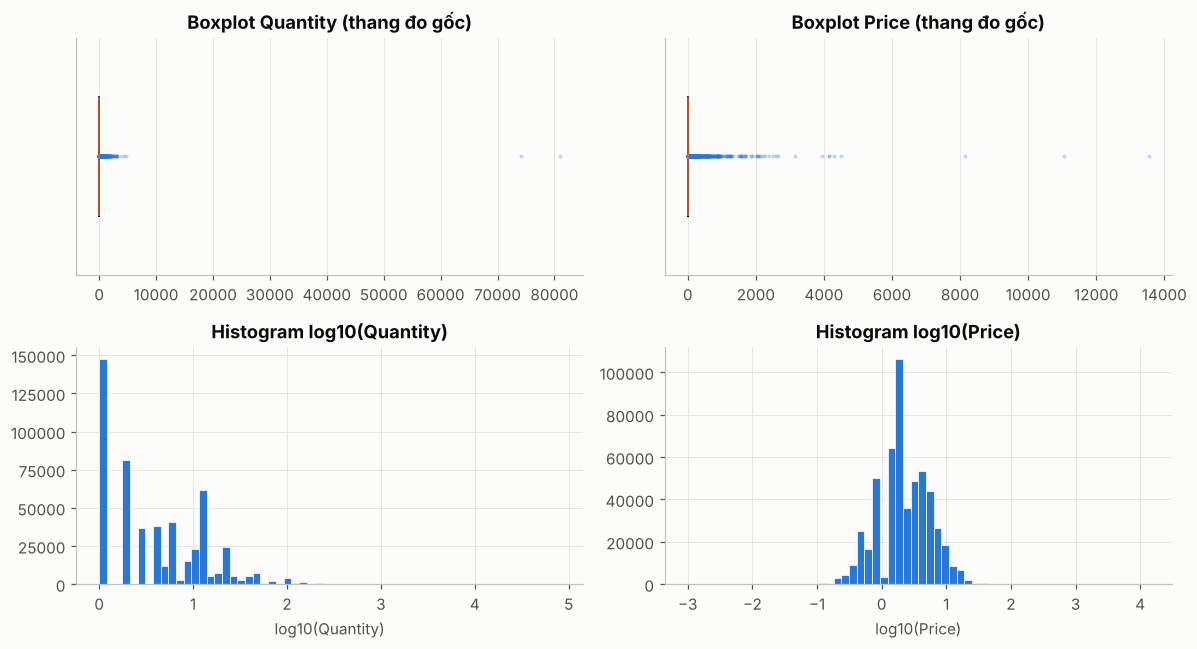

Quantity: skewness=471.7, cận trên IQR=23.50, số ngoại lệ=56,363 (10.6%)
Price: skewness=206.1, cận trên IQR=8.45, số ngoại lệ=38,000 (7.2%)


In [11]:
valid = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for j, col in enumerate(["Quantity", "Price"]):
    axes[0, j].boxplot(valid[col], vert=False, widths=0.5, flierprops=dict(marker=".", markersize=3, alpha=.3, markeredgecolor=viz.MAIN),
                       medianprops=dict(color=viz.ACCENT))
    axes[0, j].set_title(f"Boxplot {col} (thang đo gốc)"); axes[0, j].set_yticks([])
    axes[1, j].hist(np.log10(valid[col]), bins=60, color=viz.MAIN, edgecolor="#fcfcfb", linewidth=.5)
    axes[1, j].set_title(f"Histogram log10({col})"); axes[1, j].set_xlabel(f"log10({col})")
fig.tight_layout(); viz.save(fig, "fig02_quantity_price_distribution"); plt.show()

for col in ["Quantity", "Price"]:
    s = valid[col]; q1, q3 = s.quantile([.25, .75]); hi = q3 + 1.5 * (q3 - q1)
    print(f"{col}: skewness={s.skew():.1f}, cận trên IQR={hi:.2f}, số ngoại lệ={(s > hi).sum():,} ({100*(s > hi).mean():.1f}%)")

In [12]:
# Các giao dịch có số lượng/giá trị lớn nhất (kể cả hủy) - phát hiện cặp mua–hủy
big = df.assign(Value=df["Quantity"] * df["Price"]).reindex(
    df["Quantity"].abs().sort_values(ascending=False).index).head(8)
big[["Invoice", "StockCode", "Description", "Quantity", "Price", "Value", "Customer ID", "InvoiceDate"]]

,Invoice,StockCode,Description,Quantity,Price,Value,Customer ID,InvoiceDate
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"-168,469.60","16,446.00",2011-12-09 09:27:00
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60","16,446.00",2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60","12,346.00",2011-01-18 10:01:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"-77,183.60","12,346.00",2011-01-18 10:17:00
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,0.00,"13,256.00",2011-11-25 15:57:00
225529,556690,23005,printing smudges/thrown away,-9600,0.00,-0.00,NaN,2011-06-14 10:37:00
225530,556691,23005,printing smudges/thrown away,-9600,0.00,-0.00,NaN,2011-06-14 10:37:00
4268,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,-280.80,"15,838.00",2010-12-02 14:23:00


**Nhận xét:**
- Trên thang đo gốc, boxplot gần như "dẹt" vì một vài điểm cực lớn. Trên thang log10, Quantity tập trung ở 1–12 sản phẩm/dòng và Price ở khoảng 1–5 £. Độ lệch (skewness) lần lượt là 471,7 và 206,1, và theo quy tắc IQR có tới 10,6% và 7,2% số dòng là "ngoại lệ".
- Tỉ lệ ngoại lệ theo IQR cao như vậy **không có nghĩa là dữ liệu sai**: đây là đặc trưng của khách bán buôn mua số lượng lớn. Nếu loại bỏ máy móc ở cấp giao dịch sẽ làm mất chính nhóm khách giá trị cao. → **Quyết định:** không loại ngoại lệ ở cấp giao dịch, mà xử lý ở **cấp khách hàng sau khi tính RFM** (biến đổi log, và kiểm tra ảnh hưởng của capping).
- Hai giao dịch lớn nhất (80.995 và 74.215 sản phẩm, khách 16446 và 12346) đều **bị hủy ngay sau đó vài phút** (cặp hóa đơn mua và hóa đơn "C"). Nếu chỉ bỏ hóa đơn hủy mà không trừ ngược, hai khách này sẽ có Monetary ảo hơn 168.000 £ và 77.000 £. Đây là lý do nhóm tính **Monetary ròng = tiền mua − tiền trả lại**.

## 6. Đặc điểm theo thời gian
Phần này và các phần sau chỉ dùng các dòng mua hàng hợp lệ (Quantity > 0, Price > 0, là sản phẩm) để phản ánh đúng hành vi mua.

Month,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
Revenue,"777,931.77","671,933.19","508,886.20","691,257.61","516,218.12","741,192.41","738,751.87","689,364.41","725,513.50","1,030,475.36","1,106,669.82","1,457,745.53","615,493.27"
Invoices,"1,550.00","1,081.00","1,093.00","1,440.00","1,235.00","1,668.00","1,525.00","1,452.00","1,339.00","1,818.00","2,005.00","2,751.00",816.00
Customers,884.00,739.00,757.00,973.00,853.00,"1,054.00",990.00,946.00,933.00,"1,259.00","1,361.00","1,660.00",614.00


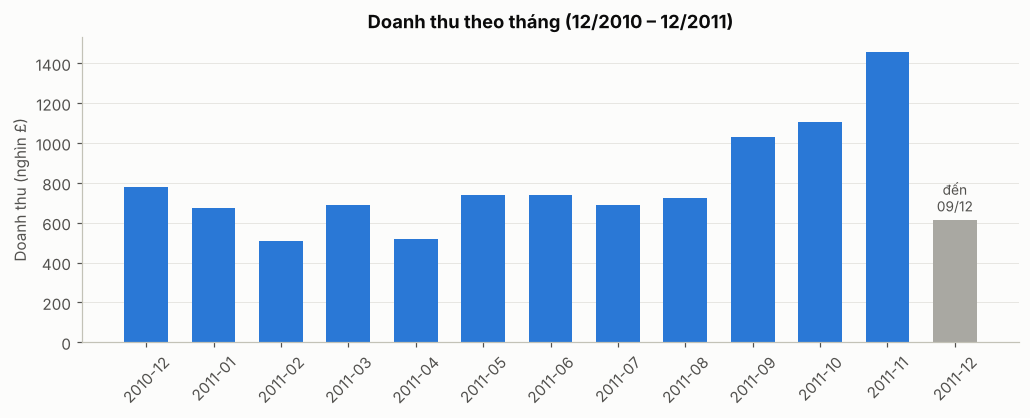

In [13]:
sales = valid[~is_non_product(valid["StockCode"])].copy()
sales["Revenue"] = sales["Quantity"] * sales["Price"]
sales["Month"] = sales["InvoiceDate"].dt.to_period("M")

monthly = sales.groupby("Month").agg(Revenue=("Revenue", "sum"), Invoices=("Invoice", "nunique"),
                                     Customers=("Customer ID", "nunique"))
display(monthly.T)

fig, ax = plt.subplots(figsize=(11, 3.6))
x = monthly.index.astype(str)
ax.bar(x, monthly["Revenue"] / 1e3, color=viz.MAIN, width=0.65)
ax.bar(x[-1], monthly["Revenue"].iloc[-1] / 1e3, color=viz.GREY, width=0.65)
ax.text(len(x) - 1, monthly["Revenue"].iloc[-1] / 1e3 + 25, "đến\n09/12", ha="center", va="bottom", color=viz.INK2, fontsize=9)
ax.set_ylabel("Doanh thu (nghìn £)"); ax.set_title("Doanh thu theo tháng (12/2010 – 12/2011)")
ax.grid(axis="x", visible=False); plt.xticks(rotation=45)
viz.save(fig, "fig03_monthly_revenue"); plt.show()

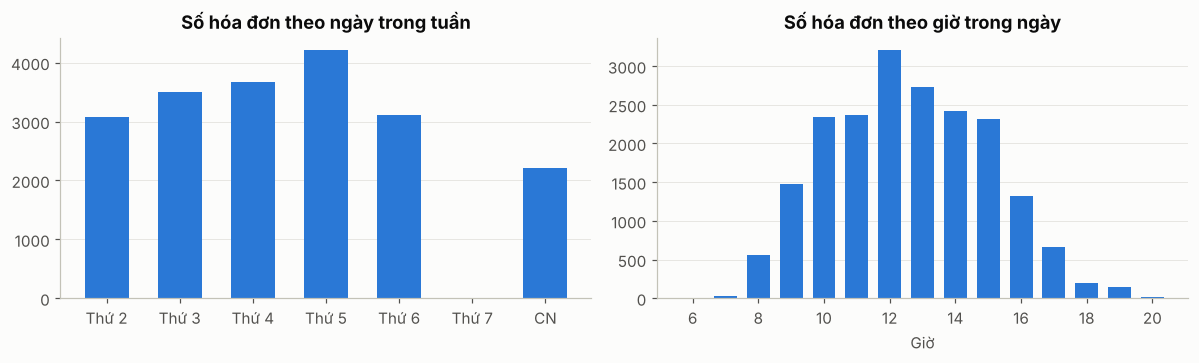

Số hóa đơn thứ 7: 0


In [14]:
dow_names = ["Thứ 2", "Thứ 3", "Thứ 4", "Thứ 5", "Thứ 6", "Thứ 7", "CN"]
inv = sales.drop_duplicates("Invoice")
by_dow = inv["InvoiceDate"].dt.dayofweek.value_counts().reindex(range(7), fill_value=0)
by_hour = inv["InvoiceDate"].dt.hour.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar(dow_names, by_dow.values, color=viz.MAIN, width=.6)
axes[0].set_title("Số hóa đơn theo ngày trong tuần"); axes[0].grid(axis="x", visible=False)
axes[1].bar(by_hour.index, by_hour.values, color=viz.MAIN, width=.7)
axes[1].set_title("Số hóa đơn theo giờ trong ngày"); axes[1].set_xlabel("Giờ"); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); viz.save(fig, "fig04_invoices_dow_hour"); plt.show()
print("Số hóa đơn thứ 7:", by_dow.iloc[5])

**Nhận xét:**
- Doanh thu khá ổn định ở mức khoảng 500–780 nghìn £/tháng trong nửa đầu năm, sau đó **tăng mạnh từ tháng 9 và đạt đỉnh vào tháng 11/2011** (khoảng 1,46 triệu £, gần gấp đôi trung bình). Điều này phù hợp với mùa mua sắm quà tặng Giáng sinh. Tháng 12/2011 chỉ có dữ liệu đến ngày 09/12 nên thấp hơn.
- **Không có giao dịch nào vào thứ Bảy**, và hoạt động tập trung từ thứ 3 đến thứ 5, đông nhất trong khung **10h–15h** (đỉnh lúc 12h). Đây là dấu hiệu của **khách hàng doanh nghiệp/bán buôn** đặt hàng trong giờ hành chính.
- Hệ quả cho RFM: ngày tham chiếu (snapshot) được chọn là **10/12/2011** (ngày sau giao dịch cuối cùng). Do tính mùa vụ mạnh, khách mua dịp cuối năm sẽ có Recency thấp; cần lưu ý điều này khi diễn giải các cụm.

## 7. Đặc điểm theo quốc gia

,Revenue,Customers,Invoices,% doanh thu
Country,,,,
United Kingdom,"8,747,561.66",3916,17901,85.16
Netherlands,"283,889.34",9,93,2.76
EIRE,"271,164.30",3,282,2.64
Germany,"205,569.89",94,443,2.00
France,"184,582.74",87,382,1.80
Australia,"138,171.31",9,56,1.35
Spain,"55,725.11",30,88,0.54
Switzerland,"53,087.90",21,50,0.52
Japan,"37,416.37",8,19,0.36


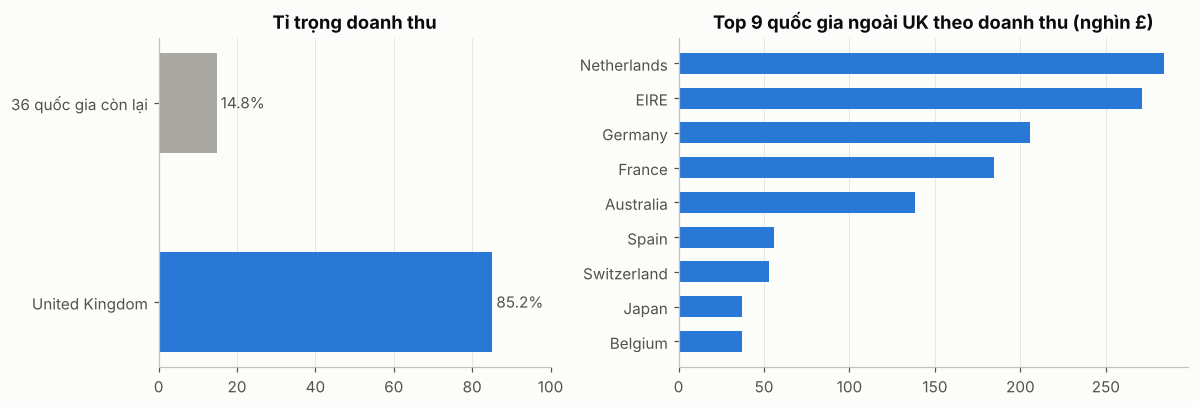

In [15]:
ctry = sales.groupby("Country").agg(Revenue=("Revenue", "sum"), Customers=("Customer ID", "nunique"),
                                    Invoices=("Invoice", "nunique")).sort_values("Revenue", ascending=False)
ctry["% doanh thu"] = 100 * ctry["Revenue"] / ctry["Revenue"].sum()
display(ctry.head(10))

top = ctry.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
share = [ctry["% doanh thu"].iloc[0], 100 - ctry["% doanh thu"].iloc[0]]
axes[0].barh(["United Kingdom", "36 quốc gia còn lại"], share, color=[viz.MAIN, viz.GREY], height=.5)
for i, v in enumerate(share):
    axes[0].text(v + 1, i, f"{v:.1f}%", va="center", color=viz.INK2)
axes[0].set_xlim(0, 100); axes[0].set_title("Tỉ trọng doanh thu"); axes[0].grid(axis="y", visible=False)
axes[1].barh(top.index[:-1], top["Revenue"][:-1] / 1e3, color=viz.MAIN, height=.6)
axes[1].set_title("Top 9 quốc gia ngoài UK theo doanh thu (nghìn £)"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); viz.save(fig, "fig05_country_revenue"); plt.show()

**Nhận xét:**
- Dữ liệu **mất cân bằng mạnh theo địa lý**: United Kingdom chiếm 85,2% doanh thu và khoảng 90% số khách hàng. 36 quốc gia còn lại chỉ chiếm 14,8%.
- Một số quốc gia có rất ít khách nhưng doanh thu lớn (Netherlands: 9 khách, EIRE: 3 khách, Australia: 9 khách), tức là các khách bán buôn lớn. Những khách này sẽ là điểm ngoại lệ ở cấp khách hàng.
- → **Quyết định:** giữ lại mọi quốc gia, vì phân khúc dựa trên hành vi chứ không dựa trên địa lý. `Country` không đưa vào mô hình phân cụm, chỉ dùng để mô tả hồ sơ cụm.

## 8. Đặc điểm sản phẩm

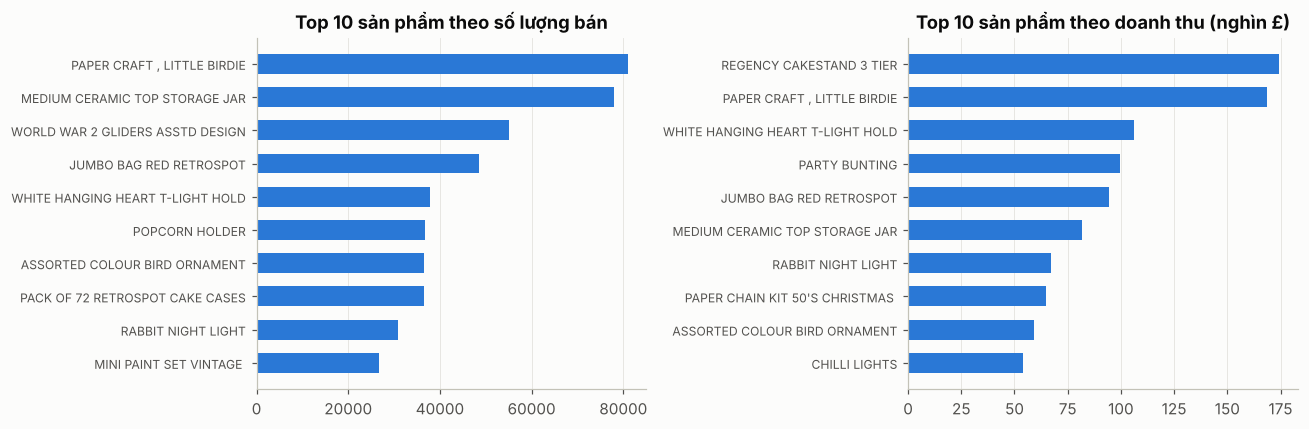

Số sản phẩm (theo Description): 4,012; 20% sản phẩm hàng đầu chiếm 78.7% doanh thu


In [16]:
prod = sales.groupby("Description").agg(Quantity=("Quantity", "sum"), Revenue=("Revenue", "sum"),
                                         Customers=("Customer ID", "nunique"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "Quantity", "Top 10 sản phẩm theo số lượng bán"),
                       (axes[1], "Revenue", "Top 10 sản phẩm theo doanh thu (nghìn £)")]:
    t = prod.nlargest(10, col).iloc[::-1]
    vals = t[col] / (1e3 if col == "Revenue" else 1)
    ax.barh([d[:32] for d in t.index], vals, color=viz.MAIN, height=.6)
    ax.set_title(title); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
fig.tight_layout(); viz.save(fig, "fig06_top_products"); plt.show()

top20_share = prod["Revenue"].nlargest(int(len(prod) * .2)).sum() / prod["Revenue"].sum()
print(f"Số sản phẩm (theo Description): {len(prod):,}; 20% sản phẩm hàng đầu chiếm {100*top20_share:.1f}% doanh thu")

**Nhận xét:**
- Doanh thu tập trung vào một nhóm nhỏ sản phẩm: **20% sản phẩm tạo ra khoảng 78,7% doanh thu**, gần với nguyên lý Pareto 80/20.
- "PAPER CRAFT, LITTLE BIRDIE" và "MEDIUM CERAMIC TOP STORAGE JAR" đứng đầu chủ yếu nhờ **hai đơn hàng khổng lồ đã bị hủy** (mục 5). Điều này một lần nữa cho thấy cần trừ giá trị trả hàng khi tính Monetary.
- Đề tài tập trung vào phân khúc khách hàng nên thông tin sản phẩm chỉ được dùng gián tiếp qua đặc trưng **NumProducts** (số sản phẩm khác nhau mỗi khách mua).

## 9. Đặc điểm cấp khách hàng (nền tảng cho RFM)

Số khách hàng có giao dịch mua hợp lệ: 4,334


,count,mean,std,min,25%,50%,75%,90%,99%,max
Invoices,"4,334.00",4.25,7.63,1.00,1.00,2.00,5.00,9.00,30.00,206.00
Revenue,"4,334.00","2,021.47","8,907.50",3.75,305.56,668.12,"1,631.62","3,589.29","18,715.31","279,138.02"


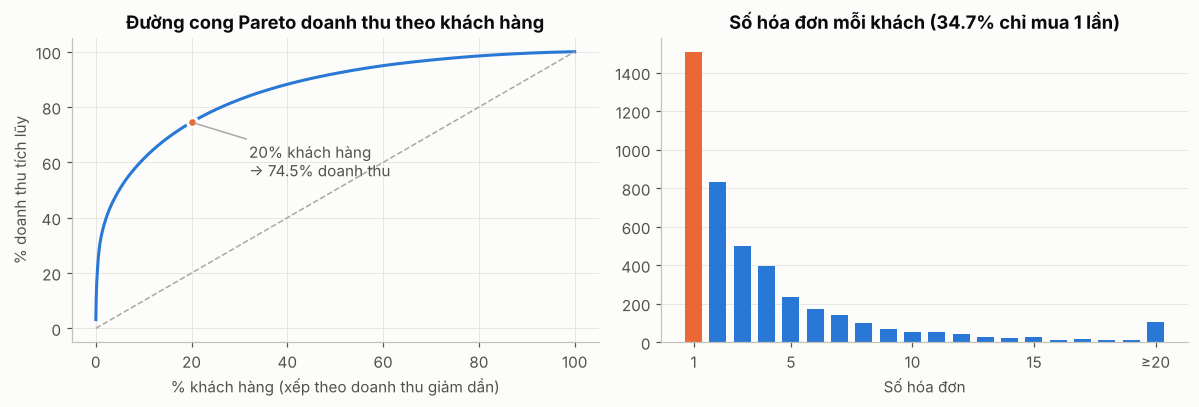

In [17]:
cust_sales = sales.dropna(subset=["Customer ID"])
cust = cust_sales.groupby("Customer ID").agg(Invoices=("Invoice", "nunique"), Revenue=("Revenue", "sum"),
                                             LastPurchase=("InvoiceDate", "max"))
print(f"Số khách hàng có giao dịch mua hợp lệ: {len(cust):,}")
display(cust[["Invoices", "Revenue"]].describe(percentiles=[.25, .5, .75, .9, .99]).T)

# Đường cong Pareto (Lorenz) doanh thu theo khách hàng
r = cust["Revenue"].sort_values(ascending=False).values
cum = np.cumsum(r) / r.sum(); pct = np.arange(1, len(r) + 1) / len(r)
share20 = cum[int(.2 * len(r)) - 1]
one_time = (cust["Invoices"] == 1).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(pct * 100, cum * 100, color=viz.MAIN)
axes[0].plot([0, 100], [0, 100], color=viz.GREY, linestyle="--", linewidth=1)
axes[0].scatter([20], [share20 * 100], color=viz.ACCENT, s=40, zorder=3, edgecolor="#fcfcfb", linewidth=2)
axes[0].annotate(f"20% khách hàng\n→ {share20*100:.1f}% doanh thu", (20, share20 * 100), xytext=(32, 55), color=viz.INK2,
                 arrowprops=dict(arrowstyle="-", color=viz.GREY))
axes[0].set_xlabel("% khách hàng (xếp theo doanh thu giảm dần)"); axes[0].set_ylabel("% doanh thu tích lũy")
axes[0].set_title("Đường cong Pareto doanh thu theo khách hàng")
cnt = cust["Invoices"].clip(upper=20).value_counts().sort_index()
axes[1].bar(cnt.index, cnt.values, color=[viz.ACCENT if i == 1 else viz.MAIN for i in cnt.index], width=.7)
axes[1].set_xticks([1, 5, 10, 15, 20]); axes[1].set_xticklabels(["1", "5", "10", "15", "≥20"])
axes[1].set_title(f"Số hóa đơn mỗi khách ({one_time*100:.1f}% chỉ mua 1 lần)"); axes[1].set_xlabel("Số hóa đơn")
axes[1].grid(axis="x", visible=False)
fig.tight_layout(); viz.save(fig, "fig07_customer_pareto_frequency"); plt.show()

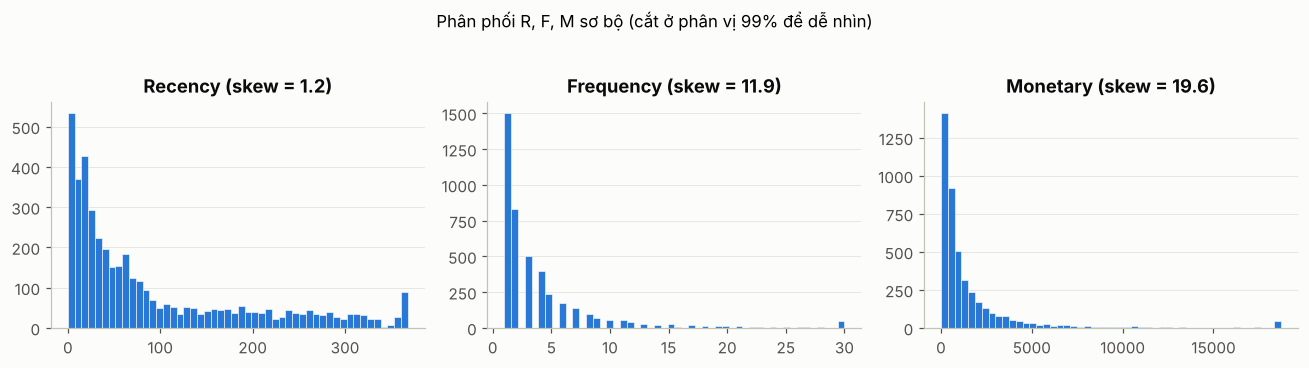

,Recency,Frequency,Monetary
Recency,1.00,-0.56,-0.48
Frequency,-0.56,1.00,0.81
Monetary,-0.48,0.81,1.00


In [18]:
# Phân phối thô của 3 đại lượng R, F, M (tính nhanh, chưa xử lý hủy đơn) – minh họa độ lệch
snap = cust_sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
quick = pd.DataFrame({"Recency": (snap - cust["LastPurchase"]).dt.days,
                      "Frequency": cust["Invoices"], "Monetary": cust["Revenue"]})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, quick.columns):
    ax.hist(quick[c].clip(upper=quick[c].quantile(.99)), bins=50, color=viz.MAIN, edgecolor="#fcfcfb", linewidth=.4)
    ax.set_title(f"{c} (skew = {quick[c].skew():.1f})"); ax.grid(axis="x", visible=False)
fig.suptitle("Phân phối R, F, M sơ bộ (cắt ở phân vị 99% để dễ nhìn)", y=1.03, fontsize=11)
fig.tight_layout(); viz.save(fig, "fig08_rfm_raw_preview"); plt.show()
quick.corr(method="spearman")

**Nhận xét:**
- Có 4.334 khách hàng có giao dịch mua hợp lệ. Trung vị là 2 hóa đơn và 668 £/khách, nhưng trung bình là 4,25 hóa đơn và 2.021 £. Khoảng cách lớn giữa trung bình và trung vị cho thấy **phân phối lệch phải mạnh**.
- **Đường cong Pareto:** khoảng 20% khách hàng tạo ra khoảng 74,5% doanh thu. Đây là cơ sở thực tiễn cho việc phân khúc: các nhóm khách hàng có giá trị rất khác nhau nên cần chiến lược chăm sóc khác nhau.
- **Khoảng 34,7% khách chỉ mua đúng 1 lần.** Frequency có rất nhiều giá trị trùng ở mức thấp, vì vậy khi chấm điểm RFM theo phân vị phải xếp hạng (rank) trước khi chia nhóm.
- **Phân phối R, F, M đều lệch phải** (skewness lần lượt 1,2, 11,9 và 19,6). Thuật toán dựa trên khoảng cách Euclid như K-Means sẽ bị các điểm cực trị chi phối nếu dùng dữ liệu gốc. → Cần **biến đổi log1p và chuẩn hóa** trước khi phân cụm.
- **Tương quan Spearman:** F và M tương quan mạnh (0,81), còn R tương quan nghịch vừa phải với F (−0,56) và M (−0,48). Ba chiều có thông tin chồng lấn nhưng không trùng nhau hoàn toàn, nên việc giữ cả ba chiều là hợp lý.

## 10. Tổng kết EDA và quyết định tiền xử lý

### Tóm tắt các phát hiện chính
| # | Vấn đề phát hiện | Mức độ | Quyết định tiền xử lý (notebook 02) |
|---|---|---|---|
| 1 | 5.268 dòng trùng lặp hoàn toàn | 0,97% | Loại bỏ |
| 2 | Customer ID thiếu (bao gồm toàn bộ dòng thiếu Description và dòng điều chỉnh kho) | 24,93% | Loại bỏ, vì không gán được cho khách hàng |
| 3 | Hóa đơn hủy "C" (Quantity âm) | 1,71% | Tách riêng; dùng để tính Monetary ròng và ReturnRate |
| 4 | Price ≤ 0, hóa đơn điều chỉnh "A" | ~0,5% | Loại bỏ |
| 5 | Mã không phải sản phẩm (POST, DOT, M, AMAZONFEE…) | 0,54% | Loại bỏ |
| 6 | Ngoại lệ Quantity/Price ở cấp giao dịch (khách bán buôn) | 7–11% theo IQR | Giữ lại; xử lý ở cấp khách hàng |
| 7 | Cặp đơn mua–hủy khổng lồ (khách 16446, 12346) | 2 khách | Monetary ròng = mua − trả |
| 8 | R, F, M lệch phải mạnh, có thang đo khác nhau | skew 1,2–19,6 | log1p + StandardScaler; kiểm tra capping |
| 9 | Tính mùa vụ (đỉnh tháng 11), dữ liệu kết thúc 09/12/2011 | – | Snapshot = 10/12/2011; lưu ý khi diễn giải |

### Đặc điểm nổi bật của dữ liệu cần trình bày trong báo cáo
1. Dữ liệu **giao dịch** cần được tổng hợp về cấp **khách hàng**.
2. Khách hàng chủ yếu ở UK, có tỉ lệ bán buôn cao, mua trong giờ hành chính.
3. Giá trị khách hàng **phân bố rất không đều** (Pareto 20/75), và 1/3 số khách chỉ mua một lần. Đây là động lực để thực hiện phân khúc.
4. Phân phối lệch và nhiều ngoại lệ là thách thức chính đối với các thuật toán phân cụm, đồng thời là lý do để so sánh nhiều thuật toán có giả định khác nhau (K-Means, GMM, Hierarchical, HDBSCAN).